# Spaceship Titanic

## Data Import

This exercise is based on a dataset splitted in three files.

1. train.csv: Training data
2. test.csv: Test data wo target column
3. sample_submission.csv: Test ids with the target column to be filled by the prediction

We are going to work exclusively with the train dataset. First we will import the `NormalizadorDataset` class to clean and dummify the dataset preparing it for the prediction we will make using ANN.

In [1]:
import numpy as np, pandas as pd
import numpy as np, matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier
import tensorflow as tf

from src.normalizador import NormalizadorDataset
from src.resultados import reporte_modelo, obtener_probabilidades

I0000 00:00:1792256029.270470     750 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792256029.560379     750 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792256034.606070     750 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792256078.516246     750 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
# Let's define the expenses (GASTOS)
GASTOS = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

# Will not use TotalSpent since HistGradientBoostingClassifier score 
# doesn't improve compared to use individual expenses
# Will create NoSpend since Correlation between CryoSleep and TotalSpent
# was negative

# NoSpend didn't improve the score, will remove it as well

def features(df):
    df = df.copy()
    df["Group"] = df["PassengerId"].str.split("_").str[0]
    df["GroupSize"] = df.groupby("Group")["Group"].transform("size")
    df[["Deck", "CabinNum", "Side"]] = df["Cabin"].str.split("/", expand=True)
    df["CabinNum"] = pd.to_numeric(df["CabinNum"])
    # df["TotalSpend"] = df[GASTOS].sum(axis=1)

    # df["NoSpend"] = (df[GASTOS].sum(axis=1) == 0)
    for c in GASTOS:
        df[c] = np.log1p(df[c])
    return df.drop(columns=["Cabin", "Name"])

In [3]:
# CSV Import
train = features(pd.read_csv("data/raw/train.csv"))
test  = features(pd.read_csv("data/raw/test.csv"))

train.head(5)

,PassengerId,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Group,GroupSize,Deck,CabinNum,Side
0,0001_01,Europa,False,TRAPPIST-1e,39.0,False,0.000000,0.000000,0.000000,0.000000,0.000000,False,0001,1,B,0.0,P
1,0002_01,Earth,False,TRAPPIST-1e,24.0,False,4.700480,2.302585,3.258097,6.309918,3.806662,True,0002,1,F,0.0,S
2,0003_01,Europa,False,TRAPPIST-1e,58.0,True,3.784190,8.182280,0.000000,8.812248,3.912023,False,0003,2,A,0.0,S
3,0003_02,Europa,False,TRAPPIST-1e,33.0,False,0.000000,7.157735,5.918894,8.110728,5.267858,False,0003,2,A,0.0,S
4,0004_01,Earth,False,TRAPPIST-1e,16.0,False,5.717028,4.262680,5.023881,6.338594,1.098612,True,0004,1,F,1.0,S


In [4]:
# split 80/20 stratified and wo splitting groups
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train, train["Transported"], groups=train["Group"]))
tr, va = train.iloc[tr_idx], train.iloc[va_idx]

In [5]:
# the normalizador reads the files -> then we save only the train
tr.drop(columns="Group").to_csv("data/processed/train_split.csv", index=False)
norm = NormalizadorDataset("data/processed/train_split.csv", columnas_excluir=["Transported"])
norm.preview()
df_tr = norm.procesar("zscore", "moda")

Archivo: train_split.csv | filas: 6954 | columnas: 16

  PassengerId HomePlanet CryoSleep  Destination   Age    VIP  RoomService  FoodCourt  ShoppingMall       Spa    VRDeck  Transported  GroupSize Deck  CabinNum Side
0     0001_01     Europa     False  TRAPPIST-1e  39.0  False     0.000000   0.000000      0.000000  0.000000  0.000000        False          1    B       0.0    P
1     0002_01      Earth     False  TRAPPIST-1e  24.0  False     4.700480   2.302585      3.258097  6.309918  3.806662         True          1    F       0.0    S
2     0003_01     Europa     False  TRAPPIST-1e  58.0   True     3.784190   8.182280      0.000000  8.812248  3.912023        False          2    A       0.0    S
3     0003_02     Europa     False  TRAPPIST-1e  33.0  False     0.000000   7.157735      5.918894  8.110728  5.267858        False          2    A       0.0    S
4     0004_01      Earth     False  TRAPPIST-1e  16.0  False     5.717028   4.262680      5.023881  6.338594  1.098612         Tru

/mnt/c/Users/odver/OneDrive/Documentos/Newton-Forge/NN/src/normalizador.py:217: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].fillna(valor)


In [6]:
df_tr.head(5)

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,...,GroupSize_7,GroupSize_8,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T
0,1,0,2,0.712488,0,-0.654483,-0.667458,-0.641439,-0.678583,-0.658360,...,0,0,0,1,0,0,0,0,0,0
1,0,0,2,-0.338114,0,1.083376,0.123271,0.631938,1.624260,0.732619,...,0,0,0,0,0,0,0,1,0,0
2,1,0,2,2.043251,1,0.744605,2.142413,-0.641439,2.537501,0.771118,...,0,0,1,0,0,0,0,0,0,0
3,1,0,2,0.292247,0,-0.654483,1.790575,1.671870,2.281476,1.266549,...,0,0,1,0,0,0,0,0,0,0
4,0,0,2,-0.898436,0,1.459213,0.796386,1.322067,1.634726,-0.256920,...,0,0,0,0,0,0,0,1,0,0


In [7]:
X_tr = df_tr.drop(columns="Transported");  y_tr = df_tr["Transported"].astype(int)
X_va = norm.transformar(va.drop(columns="Group")).drop(columns="Transported")
y_va = va["Transported"].astype(int)
X_te = norm.transformar(test.drop(columns="Group")).drop(columns="Transported")

/mnt/c/Users/odver/OneDrive/Documentos/Newton-Forge/NN/src/normalizador.py:402: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].fillna(valor)
/mnt/c/Users/odver/OneDrive/Documentos/Newton-Forge/NN/src/normalizador.py:402: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].fillna(valor)


In [8]:
X_te

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,...,GroupSize_7,GroupSize_8,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T
0,0,1,2,-0.127994,0,-0.654483,-0.667458,-0.641439,-0.678583,-0.658360,...,0,0,0,0,0,0,0,0,1,0
1,0,0,2,-0.688315,0,-0.654483,0.123271,-0.641439,2.221325,-0.658360,...,0,0,0,0,0,0,0,1,0,0
2,1,1,0,0.152167,0,-0.654483,-0.667458,-0.641439,-0.678583,-0.658360,...,0,0,0,0,1,0,0,0,0,0
3,1,0,2,0.642448,0,-0.654483,2.355513,-0.641439,1.220651,1.670491,...,0,0,0,0,1,0,0,0,0,0
4,0,0,2,-0.618275,0,0.232066,-0.667458,1.881476,-0.678583,-0.658360,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4272,0,1,2,0.362287,0,-0.654483,-0.667458,-0.641439,-0.678583,-0.658360,...,0,0,0,0,0,0,0,0,1,0
4273,0,0,2,0.922608,0,-0.654483,1.648110,0.488218,0.196544,1.160170,...,0,0,0,0,0,0,0,1,0,0
4274,2,1,0,0.012086,0,-0.654483,-0.667458,-0.641439,-0.678583,-0.658360,...,0,0,0,0,0,1,0,0,0,0
4275,1,0,2,0.012086,0,-0.654483,2.043396,-0.641439,-0.678583,1.629629,...,0,0,0,0,0,1,0,0,0,0


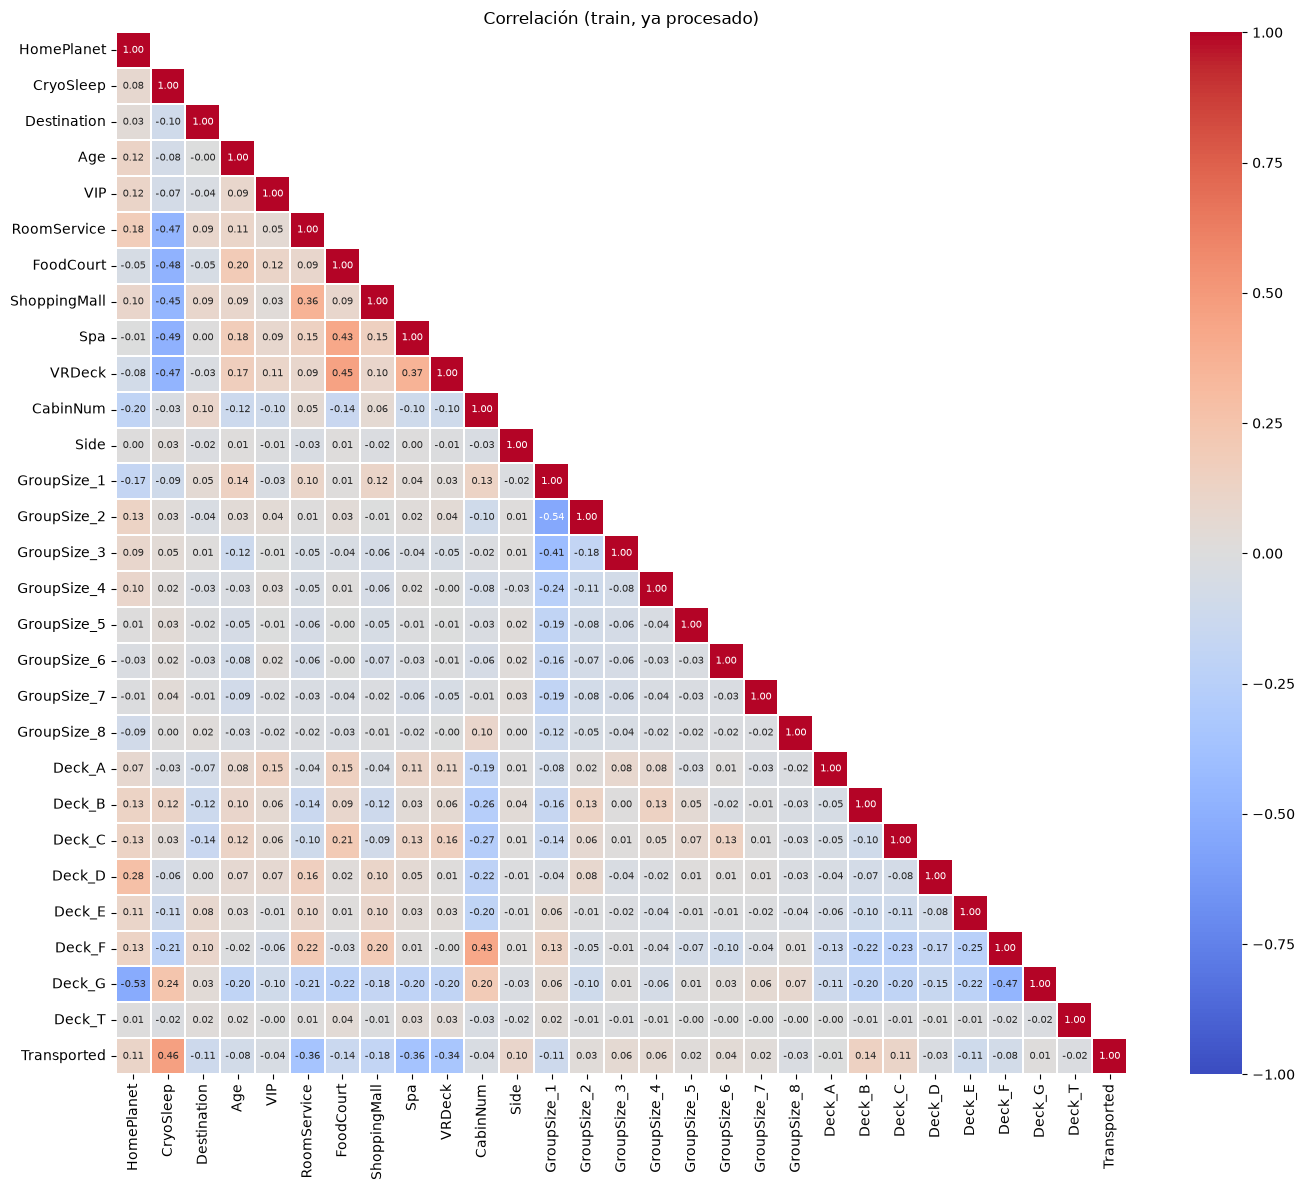

In [8]:
# 1) Heatmap including target
#    (norm.correlacion("despues") doesn't showTransported since it's bool)
d = X_tr.assign(Transported=y_tr.values)
corr = d.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(14, 12))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.3)
plt.title("Correlación (train, ya procesado)")
plt.tight_layout(); plt.show()

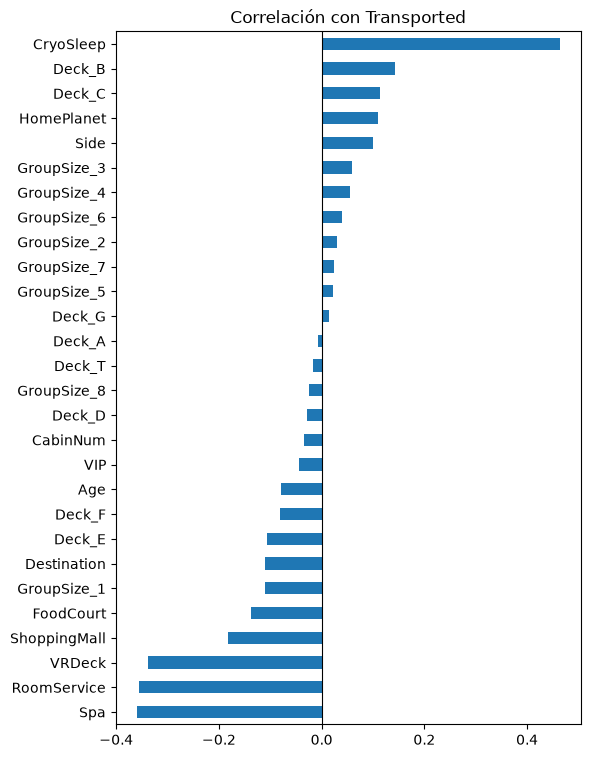

In [9]:
# 2) Correlation of each feature with the target
corr["Transported"].drop("Transported").sort_values().plot.barh(figsize=(6, 9))
plt.axvline(0, color="k", lw=0.8); plt.title("Correlación con Transported"); plt.show()


In [10]:
todas = list(X_tr.columns)
variantes = {
    "todas":               todas,
    # "solo NoSpend":     [c for c in todas if c not in GASTOS],
    # "solo gastos indiv.":  [c for c in todas if c != "NoSpend"],
    # "solo gastos indiv.":  [c for c in todas if c != "TotalSpend"],
}
for nombre, cols in variantes.items():
    m = HistGradientBoostingClassifier(random_state=0).fit(X_tr[cols], y_tr)
    print(f"{nombre:20s} acc val = {m.score(X_va[cols], y_va):.4f}")

todas                acc val = 0.8108


In [11]:
X_tr.shape

(6954, 28)

In [12]:
# Red Neuronal de Regresión Lineal
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_tr.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

model.compile(
    # optimizer = "sgd", # Regla de actualización
    optimizer = tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                         restore_best_weights=True)


E0000 00:00:1792250341.824892   31152 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [13]:
history = model.fit(
    X_tr.astype("float32"), y_tr,
    validation_data=(X_va.astype("float32"), y_va),
    epochs=300, batch_size=64, verbose=0
)

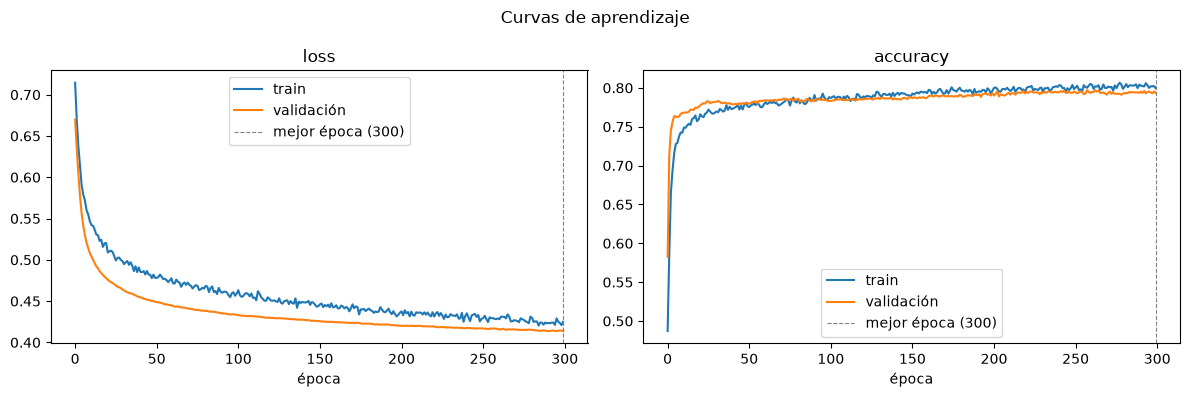

Validación: 1739 registros | positivos: 50.4%
umbral       0.5000
accuracy     0.7936
precision    0.7968
recall       0.7922
f1           0.7945
roc_auc      0.8865 

                 precision    recall  f1-score   support

No transportado     0.7903    0.7949    0.7926       863
   Transportado     0.7968    0.7922    0.7945       876

       accuracy                         0.7936      1739
      macro avg     0.7936    0.7936    0.7936      1739
   weighted avg     0.7936    0.7936    0.7936      1739



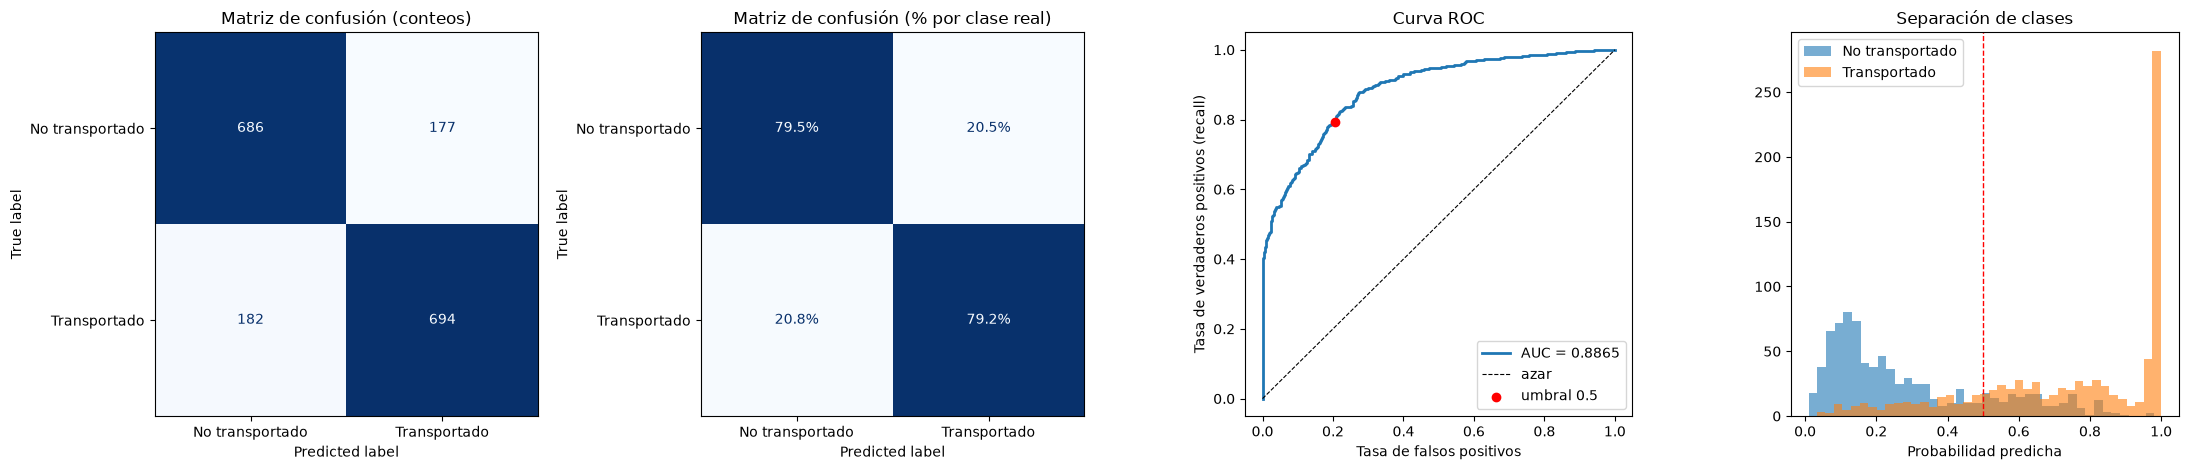

Umbral óptimo en validación: 0.38 (accuracy 0.8022 vs 0.7936 con 0.5)


In [14]:
res = reporte_modelo(model, X_va, y_va, history=history, carpeta_salida="reportes")

Predichos como Transportado en test: 50.2%
Transportados en train real:         50.4%


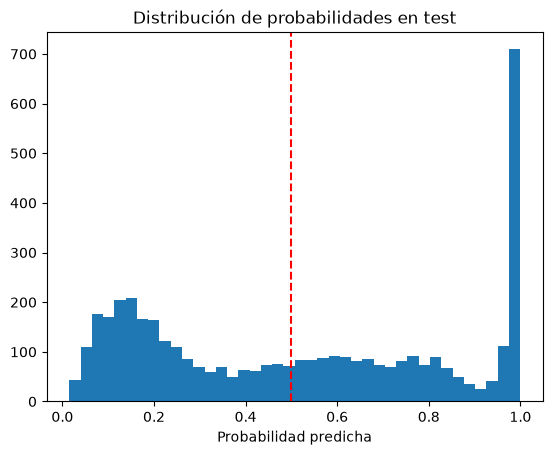

In [16]:
proba_te = obtener_probabilidades(model, X_te)
pred_te = proba_te >= 0.5

print(f"Predichos como Transportado en test: {pred_te.mean():.1%}")
print(f"Transportados en train real:         {y_tr.mean():.1%}")

plt.hist(proba_te, bins=40)
plt.axvline(0.5, color="red", ls="--")
plt.title("Distribución de probabilidades en test")
plt.xlabel("Probabilidad predicha"); plt.show()

sub = pd.read_csv("data/raw/sample_submission.csv")
sub["Transported"] = pred_te
sub.to_csv("submission.csv", index=False)